In [1]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    Trainer,
    TrainingArguments,
)
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

In [2]:
PROJECT_ROOT = Path.cwd().parent

TEST_PATH = PROJECT_ROOT / "data" / "processed" / "test.jsonl"

MODEL_PATHS = {
    "UmBERTo": PROJECT_ROOT / "models" / "umberto-ner-best",
    "XLM-RoBERTa": PROJECT_ROOT / "models" / "xlmr-ner-best",
}

print("Test dataset:", TEST_PATH)
print("Test dataset exists:", TEST_PATH.exists())

for name, path in MODEL_PATHS.items():
    print(f"{name}: {path} — exists: {path.exists()}")

Test dataset: /home/manuel/Universidade/Mestrado/NLP/project/data/processed/test.jsonl
Test dataset exists: True
UmBERTo: /home/manuel/Universidade/Mestrado/NLP/project/models/umberto-ner-best — exists: True
XLM-RoBERTa: /home/manuel/Universidade/Mestrado/NLP/project/models/xlmr-ner-best — exists: True


In [3]:
with open(TEST_PATH, "r", encoding="utf-8") as f:
    test_data = [json.loads(line) for line in f if line.strip()]

test_df = pd.DataFrame(test_data)

print("Number of examples:", len(test_df))
print("Columns:", test_df.columns.tolist())
print(test_df.head(3))

Number of examples: 4126
Columns: ['tokens', 'labels', 'domain']
                                              tokens  \
0                            [Discorso, alla, Dieta]   
1  [Ho, domandato, la, parola, per, una, breve, d...   
2  [Anzitutto, noi, consideriamo, il, passaggio, ...   

                                              labels domain  
0                                      [O, O, B-ORG]    adg  
1                        [O, O, O, O, O, O, O, O, O]    adg  
2  [O, O, O, O, O, O, O, O, O, O, O, O, O, O, O, ...    adg  


In [4]:
{
    "tokens": ["Mario", "Rossi", "vive", "em", "Roma"],
    "labels": ["B-PER", "I-PER", "O", "O", "B-LOC"],
    "domain": "ADG"
}

{'tokens': ['Mario', 'Rossi', 'vive', 'em', 'Roma'],
 'labels': ['B-PER', 'I-PER', 'O', 'O', 'B-LOC'],
 'domain': 'ADG'}

In [5]:
LABEL_LIST = [
    "O",
    "B-LOC",
    "I-LOC",
    "B-ORG",
    "I-ORG",
    "B-PER",
    "I-PER",
]

LABEL2ID = {label: idx for idx, label in enumerate(LABEL_LIST)}
ID2LABEL = {idx: label for label, idx in LABEL2ID.items()}

In [6]:
def compute_ner_metrics(eval_prediction):
    predictions, labels = eval_prediction

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.argmax(predictions, axis=2)

    true_predictions = []
    true_labels = []

    for pred_sequence, label_sequence in zip(predictions, labels):
        pred_labels = []
        gold_labels = []

        for pred_id, gold_id in zip(pred_sequence, label_sequence):
            # Ignorar tokens especiais e sub-tokens sem label
            if gold_id == -100:
                continue

            pred_labels.append(ID2LABEL[int(pred_id)])
            gold_labels.append(ID2LABEL[int(gold_id)])

        true_predictions.append(pred_labels)
        true_labels.append(gold_labels)

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
    }

In [7]:
def tokenize_test_data(tokenizer, examples, max_length=256):
    tokenized = tokenizer(
        examples["tokens"],
        is_split_into_words=True,
        truncation=True,
        max_length=max_length,
    )

    aligned_labels = []

    for i, word_labels in enumerate(examples["labels"]):
        word_ids = tokenized.word_ids(batch_index=i)
        previous_word_id = None
        label_ids = []

        for word_id in word_ids:
            if word_id is None:
                label_ids.append(-100)
            elif word_id != previous_word_id:
                label_ids.append(LABEL2ID[word_labels[word_id]])
            else:
                label_ids.append(-100)

            previous_word_id = word_id

        aligned_labels.append(label_ids)

    tokenized["labels"] = aligned_labels
    return tokenized

In [8]:
results = []

for model_name, model_path in MODEL_PATHS.items():
    print(f"\nEvaluating {model_name}...")

    tokenizer = AutoTokenizer.from_pretrained(str(model_path))

    model = AutoModelForTokenClassification.from_pretrained(
        str(model_path)
    )

    examples = {
        "tokens": test_df["tokens"].tolist(),
        "labels": test_df["labels"].tolist(),
    }

    tokenized = tokenize_test_data(
        tokenizer,
        examples,
        max_length=256,
    )

    test_dataset = Dataset.from_dict({
        "input_ids": tokenized["input_ids"],
        "attention_mask": tokenized["attention_mask"],
        "labels": tokenized["labels"],
    })

    args = TrainingArguments(
        output_dir=str(PROJECT_ROOT / "evaluation_output" / model_name),
        per_device_eval_batch_size=1,
        report_to="none",
        fp16=torch.cuda.is_available(),
    )

    trainer = Trainer(
        model=model,
        args=args,
        compute_metrics=compute_ner_metrics,
    )

    metrics = trainer.evaluate(test_dataset)

    results.append({
        "Model": model_name,
        "Precision": metrics["eval_precision"],
        "Recall": metrics["eval_recall"],
        "F1": metrics["eval_f1"],
    })

    del trainer, model, tokenizer, test_dataset
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
results_df


Evaluating UmBERTo...


  0%|          | 0/4126 [00:00<?, ?it/s]


Evaluating XLM-RoBERTa...


  0%|          | 0/4126 [00:00<?, ?it/s]

,Model,Precision,Recall,F1
0,UmBERTo,0.895593,0.893372,0.894481
1,XLM-RoBERTa,0.878643,0.869928,0.874264


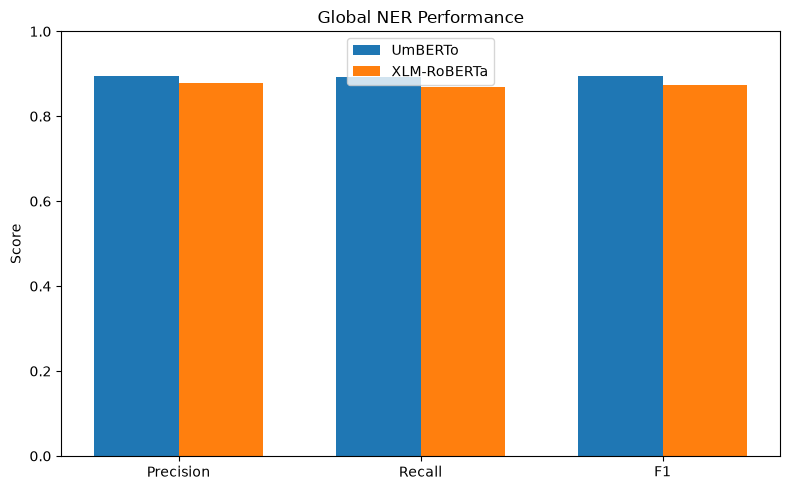

In [9]:
metrics = ["Precision", "Recall", "F1"]
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

for i, (_, row) in enumerate(results_df.iterrows()):
    values = [row[m] for m in metrics]
    ax.bar(x + (i - 0.5) * width, values, width, label=row["Model"])

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Global NER Performance")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
ENTITY_TYPES = ["PER", "ORG", "LOC"]
entity_results = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def evaluate_entity_f1(model_name, model_path, test_data):

    tokenizer = AutoTokenizer.from_pretrained(str(model_path))
    model = AutoModelForTokenClassification.from_pretrained(
        str(model_path)
    ).to(device)

    true_sequences = []
    pred_sequences = []

    for example in test_data:
        tokens = example["tokens"]
        true_labels = example["labels"]

        encoded = tokenizer(
            tokens,
            is_split_into_words=True,
            truncation=True,
            max_length=256,
            return_tensors="pt",
        )
        word_ids = tokenizer(
            tokens,
            is_split_into_words=True,
            truncation=True,
            max_length=256,
        ).word_ids()

        encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.no_grad():
            logits = model(**encoded).logits

        predicted_ids = logits.argmax(dim=-1)[0].cpu().tolist()

        aligned_true = []
        aligned_pred = []
        previous_word_id = None

        for word_id, pred_id in zip(word_ids, predicted_ids):
            if word_id is None or word_id == previous_word_id:
                previous_word_id = word_id
                continue

            if word_id < len(true_labels):
                aligned_true.append(true_labels[word_id])
                aligned_pred.append(ID2LABEL[pred_id])

            previous_word_id = word_id

        true_sequences.append(aligned_true)
        pred_sequences.append(aligned_pred)

    report = classification_report(
        true_sequences,
        pred_sequences,
        output_dict=True,
        zero_division=0,
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return report



for model_name, model_path in MODEL_PATHS.items():
    print(f"A avaliar {model_name}...")

    report = evaluate_entity_f1(
        model_name,
        model_path,
        test_data,
    )

    # Inspecionar a estrutura devolvida pelo seqeval
    print("Chaves do relatório:", report.keys())

    for entity in ENTITY_TYPES:
        metrics = report.get(entity, {})

        entity_results.append({
            "Model": model_name,
            "Entity": entity,
            "F1": metrics.get("f1-score", 0.0),
        })

entity_results_df = pd.DataFrame(entity_results)
display(entity_results_df)


A avaliar UmBERTo...
Chaves do relatório: dict_keys(['LOC', 'ORG', 'PER', 'micro avg', 'macro avg', 'weighted avg'])
A avaliar XLM-RoBERTa...
Chaves do relatório: dict_keys(['LOC', 'ORG', 'PER', 'micro avg', 'macro avg', 'weighted avg'])


,Model,Entity,F1
0,UmBERTo,PER,0.949588
1,UmBERTo,ORG,0.839973
2,UmBERTo,LOC,0.867662
3,XLM-RoBERTa,PER,0.931975
4,XLM-RoBERTa,ORG,0.811765
5,XLM-RoBERTa,LOC,0.851465


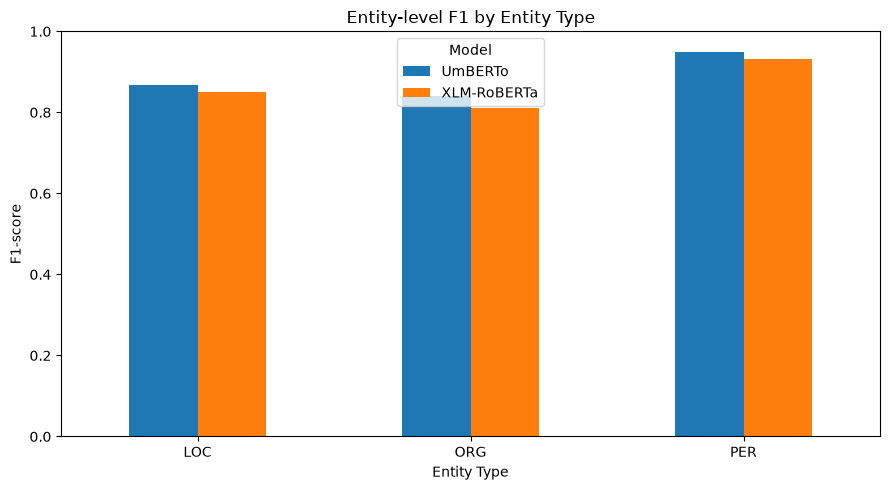

In [11]:
entity_pivot = entity_results_df.pivot(
    index="Entity",
    columns="Model",
    values="F1",
)

ax = entity_pivot.plot(kind="bar", figsize=(9, 5))
ax.set_title("Entity-level F1 by Entity Type")
ax.set_xlabel("Entity Type")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
report = evaluate_entity_f1(
    "UmBERTo",
    MODEL_PATHS["UmBERTo"],
    test_data[:20],
)

print(report)

{'LOC': {'precision': np.float64(0.7777777777777778), 'recall': np.float64(0.875), 'f1-score': np.float64(0.823529411764706), 'support': np.int64(8)}, 'ORG': {'precision': np.float64(0.6666666666666666), 'recall': np.float64(0.3333333333333333), 'f1-score': np.float64(0.4444444444444444), 'support': np.int64(6)}, 'micro avg': {'precision': np.float64(0.75), 'recall': np.float64(0.6428571428571429), 'f1-score': np.float64(0.6923076923076924), 'support': np.int64(14)}, 'macro avg': {'precision': np.float64(0.7222222222222222), 'recall': np.float64(0.6041666666666666), 'f1-score': np.float64(0.6339869281045751), 'support': np.int64(14)}, 'weighted avg': {'precision': np.float64(0.7301587301587301), 'recall': np.float64(0.6428571428571429), 'f1-score': np.float64(0.6610644257703082), 'support': np.int64(14)}}


In [13]:
domain_results = []

domains = sorted(set(
    example["domain"].lower()
    for example in test_data
))

for model_name, model_path in MODEL_PATHS.items():
    for domain in domains:
        domain_data = [
            example
            for example in test_data
            if example["domain"].lower() == domain
        ]

        print(f"A avaliar {model_name} — {domain}...")

        report = evaluate_entity_f1(
            model_name,
            model_path,
            domain_data,
        )

        # O seqeval usa "micro avg" para as métricas globais
        overall_metrics = report.get("micro avg", {})

        domain_results.append({
            "Model": model_name,
            "Domain": domain.upper(),
            "Precision": overall_metrics.get("precision", 0.0),
            "Recall": overall_metrics.get("recall", 0.0),
            "F1": overall_metrics.get("f1-score", 0.0),
            "Support": overall_metrics.get("support", 0),
        })

domain_results_df = pd.DataFrame(domain_results)

display(
    domain_results_df.round(4)
)


A avaliar UmBERTo — adg...
A avaliar UmBERTo — fic...
A avaliar UmBERTo — wn...
A avaliar XLM-RoBERTa — adg...
A avaliar XLM-RoBERTa — fic...
A avaliar XLM-RoBERTa — wn...


,Model,Domain,Precision,Recall,F1,Support
0,UmBERTo,ADG,0.8773,0.7767,0.8239,497
1,UmBERTo,FIC,0.9100,0.8571,0.8828,448
2,UmBERTo,WN,0.8961,0.9144,0.9051,3491
3,XLM-RoBERTa,ADG,0.8739,0.7666,0.8167,497
4,XLM-RoBERTa,FIC,0.9131,0.8683,0.8902,448
5,XLM-RoBERTa,WN,0.8751,0.8848,0.8799,3491


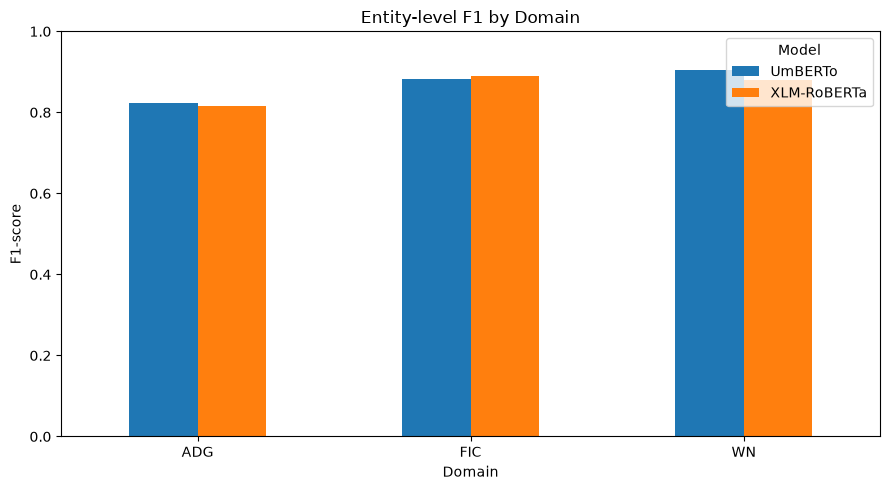

In [14]:
domain_pivot = domain_results_df.pivot(
    index="Domain",
    columns="Model",
    values="F1",
)

ax = domain_pivot.plot(
    kind="bar",
    figsize=(9, 5),
)

ax.set_title("Entity-level F1 by Domain")
ax.set_xlabel("Domain")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)
ax.legend(title="Model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
